# Лабораторная работа №2: Экспертные системы

## 1. Подготовка окружения
Импортируем необходимые библиотеки для визуализации результатов и тестирования.

In [16]:
import matplotlib.pyplot as plt 
import ipytest
import pytest

#Настройка ipytest для тесто в Jupyter
ipytest.autoconfig()

## 2. База знаний (Knowledge Base)
Класс `KnowledgeBase`, который инкапсулирует данные предметной области:
- `scenarios` - словарь возможных результатов с их характеристиками и весами.
- `questions` - словарь вопросов для пользователя, связанных с характеристиками.

In [17]:
class KnowledgeBase:
    """Класс, представляющий базу знаний экспертной системы."""
    
    def __init__(self):
        # Игра - {признаки и их веса, описание}
        self.scenarios = {
            "Cyberpunk 2077": {
                "features": {"открытый мир": 3, "киберпанк": 3, "шутер": 2, "сюжет": 2},
                "description": "Масштабная RPG в сеттинге будущего от первого лица."
            },
            "The Witcher 3": {
                "features": {"открытый мир": 3, "фэнтези": 3, "сюжет": 3, "средневековье": 2},
                "description": "Эпическая ролевая игра про охотника на чудовищ."
            },
            "CS:GO / Counter-Strike 2": {
                "features": {"мультиплеер": 3, "шутер": 3, "киберспорт": 2},
                "description": "Популярный командный тактический шутер."
            },
            "Stardew Valley": {
                "features": {"ферма": 3, "расслабляющая": 3, "инди": 2},
                "description": "Уютный симулятор жизни в деревне."
            }
        }
        
        # Вопросы для пользователя
        self.questions = {
            "открытый мир": "В игре должен быть большой открытый мир для исследования?",
            "киберпанк": "Вам нравится эстетика киберпанка и технологий будущего?",
            "шутер": "Предпочитаете динамичные перестрелки (шутер)?",
            "сюжет": "Является ли для вас важным глубокий сюжет?",
            "фэнтези": "Любите ли вы сеттинг фэнтези (магия, мечи, монстры)?",
            "средневековье": "Интересна ли вам атмосфера средневековья?",
            "мультиплеер": "Хотите играть по сети против других людей?",
            "киберспорт": "Интересует ли вас соревновательный киберспорт?",
            "ферма": "Нравятся ли вам игры про уход за фермой?",
            "расслабляющая": "Ищете ли вы расслабляющую игру без спешки?",
            "инди": "Интересны ли вам небольшие независимые игры (инди)?"
        }

## 3. Логика и интерфейс
Класс `ExpertSystem`, который принимает объект базы знаний и выполняет:
1. Опрос пользователя.
2. Подсчет баллов на основе совпадения признаков.
3. Графический вывод результатов.

In [18]:
class ExpertSystem:
    """Класс машины выводов и взаимодействия с пользователем."""
    
    def __init__(self, kb: KnowledgeBase):
        self.kb = kb
        
    def calculate_scores(self, user_answers: dict) -> dict:
        """Подсчет баллов для каждого сценария."""
        scores = {}
        for scenario_name, data in self.kb.scenarios.items():
            score = 0
            for feature, weight in data["features"].items():
                if user_answers.get(feature, False):
                    score += weight
            scores[scenario_name] = score
        return scores

    def plot_results(self, scores: dict):
        """Графическая визуализация набранных баллов."""
        sorted_scores = sorted(scores.items(), key=lambda item: item[1], reverse=True)
        games = [item[0] for item in sorted_scores]
        points = [item[1] for item in sorted_scores]

        plt.figure(figsize=(10, 4))
        # Лучший результат выделяем зеленым, остальные синим
        colors = ['#2ecc71' if i == 0 and points[0] > 0 else '#3498db' for i in range(len(games))]
        
        bars = plt.barh(games[::-1], points[::-1], color=colors[::-1])
        
        plt.xlabel('Набранные баллы', fontsize=12)
        plt.title('Результаты подбора', fontsize=14, fontweight='bold')
        plt.grid(axis='x', linestyle='--', alpha=0.7)

        for bar in bars:
            width = bar.get_width()
            plt.text(width + 0.1, bar.get_y() + bar.get_height()/2, f'{int(width)} б.', 
                     va='center', ha='left', fontsize=10, fontweight='bold')

        plt.tight_layout()
        plt.show()

    def start_consultation(self):
        """Запуск интерактивного опроса."""
        print("--- Экспертная система подбора видеоигр ---")
        print("Отвечайте 'y' (да) или 'n' (нет) на следующие вопросы:\n")
        
        user_answers = {}
        for feature_key, question_text in self.kb.questions.items():
            while True:
                answer = input(f"{question_text} (y/n): ").strip().lower()
                if answer in ['y', 'yes', 'д', 'да']:
                    user_answers[feature_key] = True
                    break
                elif answer in ['n', 'no', 'н', 'нет']:
                    user_answers[feature_key] = False
                    break
                else:
                    print("Ошибка ввода. Пожалуйста, введите 'y' или 'n'.")
        
        # Подсчет и вывод результатов
        scores = self.calculate_scores(user_answers)
        self.display_recommendation(scores)
        self.plot_results(scores)
        
    def display_recommendation(self, scores: dict):
        """Текстовый вывод результатов."""
        sorted_scores = sorted(scores.items(), key=lambda item: item[1], reverse=True)
        best_game, best_score = sorted_scores[0]
        
        print("\n" + "-"*45)
        if best_score > 0:
            print(f"Рекомендация: **{best_game}** (Баллов: {best_score})")
            print(f"Описание: {self.kb.scenarios[best_game]['description']}")
        else:
            print("⚠️ По вашим ответам ничего не найдено.")
        print("-"*45)

## 4. Тестирование
Тесты для проверки корректности работы базы знаний. (.ipytest нужен для работы в jupyter)

In [19]:
%%ipytest -v

def test_knowledge_base():
    """Проверка инициализации базы данных."""
    kb = KnowledgeBase()
    assert "The Witcher 3" in kb.scenarios
    assert len(kb.questions) > 5

def test_expert_system_scoring():
    """Проверка логики подсчета баллов."""
    kb = KnowledgeBase()
    es = ExpertSystem(kb)
    
    # Имитация ответов пользователя, подходящие для CS:GO
    mock_answers = {
        "мультиплеер": True,
        "шутер": True,
        "ферма": False
    }
    
    scores = es.calculate_scores(mock_answers)
    
    # Проверка, что CS:GO получил больше всего баллов
    assert scores["CS:GO / Counter-Strike 2"] == 6 # (3 за мультиплеер + 3 за шутер)
    assert scores["Stardew Valley"] == 0

======================================= test session starts =======================================
platform win32 -- Python 3.10.21, pytest-9.1.1, pluggy-1.6.0
rootdir: c:\ML_Reapet\practice
plugins: anyio-4.15.1
collected 2 items

t_ffbd478451b84c73a5d3e5f15a3dc85b.py ..                                                     [100%]

======================================== 2 passed in 0.01s ========================================


## 5. Запуск программы 
Инициализация объектов и запуск программы

--- Экспертная система подбора видеоигр ---
Отвечайте 'y' (да) или 'n' (нет) на следующие вопросы:


---------------------------------------------
Рекомендация: **Cyberpunk 2077** (Баллов: 10)
Описание: Масштабная RPG в сеттинге будущего от первого лица.
---------------------------------------------


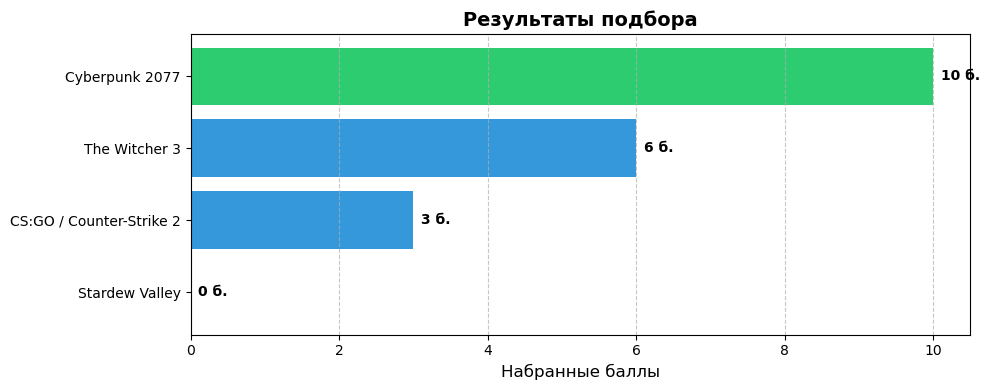

In [20]:
if __name__ == "__main__":
    # Инициализация базы знаний
    kb = KnowledgeBase()
    
    # Создание и запуск экспертной системы
    system = ExpertSystem(kb)
    
    # Раскомментить для запуска
    system.start_consultation()